In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data_folder = "../data/pp_check"
seed_data = pd.read_csv(os.path.join(data_folder, 'pp_sample_ipu.csv'))
seed_data = seed_data.drop(columns=["sample_geog"])
seed_data

,serialno,age,sex,relationship,persinc,nolicence,anywork
0,Y12H0000101,50-59,M,Main,$1000-1249 p.w.,Some Licence,Y
1,Y12H0000101,40-49,F,Spouse,$1-199 p.w.,Some Licence,N
2,Y12H0000101,10-19,F,Child,Zero Income,No Licence,N
3,Y12H0000101,0-9,F,Child,Zero Income,No Licence,N
4,Y12H0000102,50-59,F,Parent,$1-199 p.w.,Some Licence,N
...,...,...,...,...,...,...,...
75404,Y20H4001028,60-69,F,Main,$400-599 p.w.,Some Licence,Y
75405,Y20H4001029,70-79,M,Main,$300-399 p.w.,Some Licence,N
75406,Y20H4001029,70-79,F,Spouse,$300-399 p.w.,Some Licence,N
75407,Y20H4001036,70-79,F,Main,$400-599 p.w.,Some Licence,N


C:\Users\dlaa0001\AppData\Local\Temp\ipykernel_14432\3740160654.py:32: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["relationship_clean", "age_clean"])


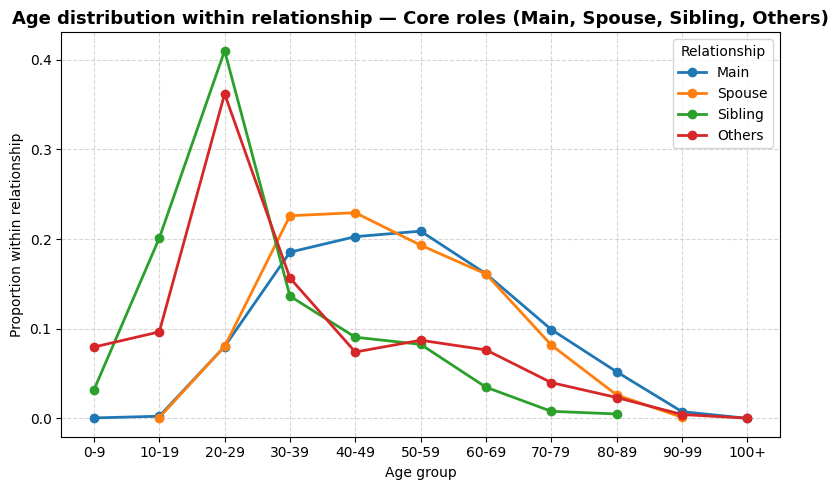

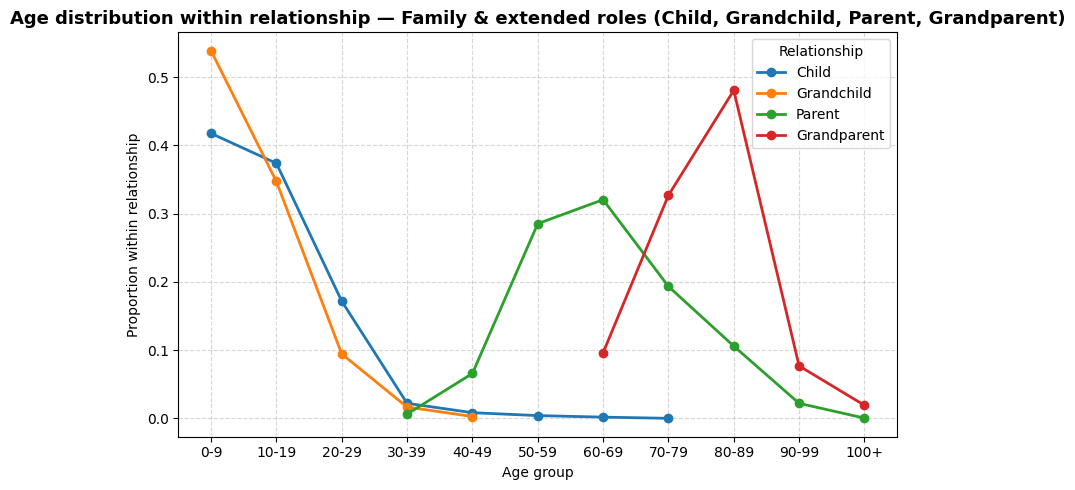

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- Prep ----------
df = seed_data.copy()

# Use exact relationships from your cleaned data; just trim spaces
df["relationship_clean"] = df["relationship"].astype(str).str.strip()

# Clean/standardise age labels and make a natural age ordering with "100+" last
df["age_clean"] = (
    df["age"].astype(str).str.strip().replace({"100 +": "100+"})
)

def _age_key(a: str) -> int:
    # works for "0-9", "10-19", ..., and "100+"
    a = a.strip()
    if a.endswith("+"):
        return 10**9  # push to end
    # handle ranges like "20-29"
    try:
        return int(a.split("-")[0])
    except Exception:
        return 10**8  # unknowns (shouldn't occur here)

age_order = sorted(df["age_clean"].dropna().unique(), key=_age_key)
df["age_clean"] = pd.Categorical(df["age_clean"], categories=age_order, ordered=True)

# Proportions WITHIN each relationship (each line sums to 1 across ages)
prop_df = (
    df.groupby(["relationship_clean", "age_clean"])
      .size()
      .groupby(level=0, group_keys=False)
      .apply(lambda s: s / s.sum())
      .reset_index(name="proportion")
)

# Hide zeros (don’t plot)
prop_df.loc[prop_df["proportion"] == 0, "proportion"] = np.nan

# ---------- Plot helper ----------
def plot_group(rel_list, title):
    plt.figure(figsize=(8, 5))
    for rel in rel_list:  # legend follows this order
        sub = prop_df[prop_df["relationship_clean"] == rel].sort_values("age_clean")
        if not sub.empty:
            plt.plot(sub["age_clean"], sub["proportion"], marker='o', linewidth=2, label=rel)
    plt.title(title, fontsize=13, weight='bold')
    plt.xlabel("Age group")
    plt.ylabel("Proportion within relationship")
    plt.legend(title="Relationship", loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    # Optional: save
    # plt.savefig("age_dist_core.png", dpi=200)
    plt.show()

# ---------- Plots ----------
core = ["Main", "Spouse", "Sibling", "Others"]
fam_ext = ["Child", "Grandchild", "Parent", "Grandparent"]

plot_group(core, "Age distribution within relationship — Core roles (Main, Spouse, Sibling, Others)")
plot_group(fam_ext, "Age distribution within relationship — Family & extended roles (Child, Grandchild, Parent, Grandparent)")


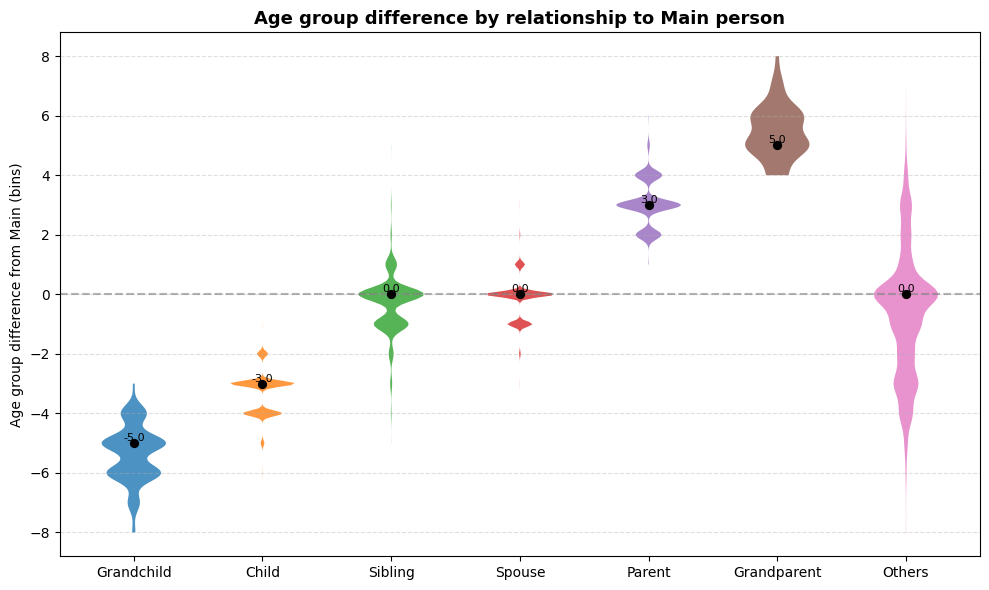

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_age_group_diff_vs_main(df: pd.DataFrame, title="Age group difference by relationship to Main person"):
    """
    df must have: serialno (household id), age (age group labels), relationship (exact labels).
    Age diff is computed in discrete bins: index(person_age_group) - index(main_age_group).
    """

    # --- 1) Clean / order age groups and map to indices ---
    age_clean = (
        df["age"].astype(str).str.strip().replace({"100 +": "100+"})
    )
    # Natural sort with "100+" last
    def _age_key(a: str) -> int:
        a = a.strip()
        if a.endswith("+"):
            return 10**9
        try:
            return int(a.split("-")[0])
        except Exception:
            return 10**8

    age_order = sorted(age_clean.dropna().unique(), key=_age_key)
    age_index_map = {age: i for i, age in enumerate(age_order)}

    df_ = df.copy()
    df_["age_clean"] = age_clean
    df_["age_index"] = df_["age_clean"].map(age_index_map).astype(float)

    # --- 2) Age index of Main per household ---
    main_age = (
        df_.loc[df_["relationship"] == "Main", ["serialno", "age_index"]]
           .dropna(subset=["age_index"])
           .drop_duplicates(subset=["serialno"])                # robust if any duplicates
           .rename(columns={"age_index": "main_age_index"})
    )

    # --- 3) Merge & compute discrete age-group difference (exclude Main) ---
    merged = (
        df_.merge(main_age, on="serialno", how="left", validate="m:1")
           .loc[df_["relationship"] != "Main"]
           .dropna(subset=["age_index", "main_age_index"])
           .assign(age_group_diff=lambda x: x["age_index"] - x["main_age_index"])
    )

    # --- 4) Prep data for violins (ordered categories) ---
    rel_order = ["Grandchild", "Child", "Sibling", "Spouse", "Parent", "Grandparent", "Others"]
    present = [r for r in rel_order if r in merged["relationship"].unique()]
    plot_data = [merged.loc[merged["relationship"] == r, "age_group_diff"].values for r in present]

    # --- 5) Plot (Matplotlib only) ---
    plt.figure(figsize=(10, 6))
    parts = plt.violinplot(plot_data, showmeans=False, showmedians=False, showextrema=False)

    # Colors + transparency
    palette = plt.cm.tab10.colors
    for i, body in enumerate(parts["bodies"]):
        body.set_facecolor(palette[i % len(palette)])
        body.set_alpha(0.8)

    # Median markers & labels
    for i, r in enumerate(present, start=1):
        vals = merged.loc[merged["relationship"] == r, "age_group_diff"].values
        if vals.size:
            med = float(np.median(vals))
            plt.scatter(i, med, color="black", s=32, zorder=3)
            plt.text(i, med, f"{med:.1f}", ha="center", va="bottom", fontsize=8)

    # Styling
    plt.axhline(0, color="gray", linestyle="--", alpha=0.6)
    plt.xticks(range(1, len(present) + 1), present)
    plt.ylabel("Age group difference from Main (bins)")
    plt.title(title, fontsize=13, weight="bold")
    plt.grid(True, linestyle="--", alpha=0.4, axis="y")
    plt.tight_layout()
    # Optional save:
    # plt.savefig("age_group_diff_vs_main.png", dpi=200)
    plt.show()

# --- Usage ---
plot_age_group_diff_vs_main(seed_data)


C:\Users\dlaa0001\AppData\Local\Temp\ipykernel_14432\2021116268.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["relationship_clean", "inc_clean"])


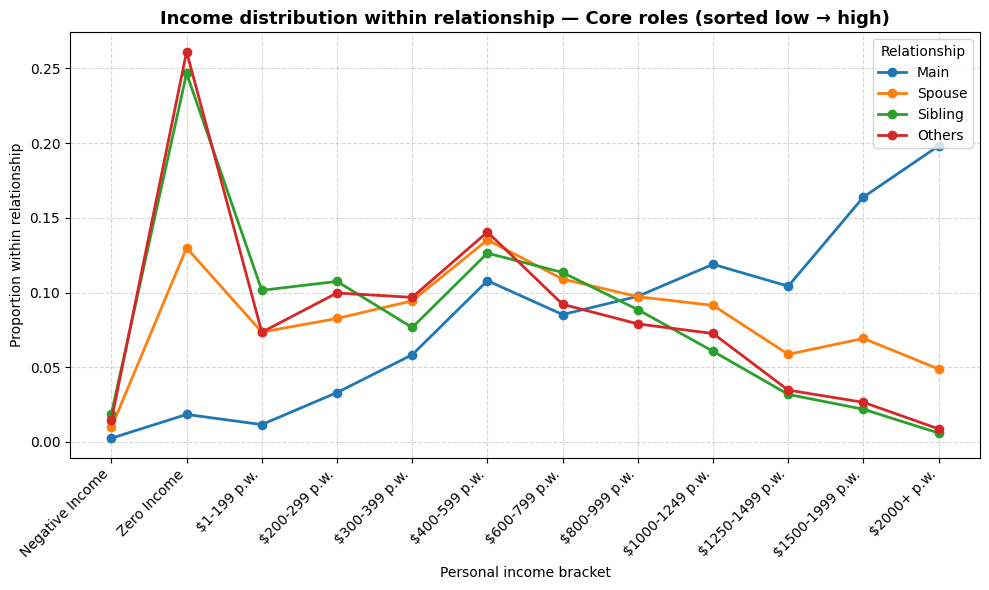

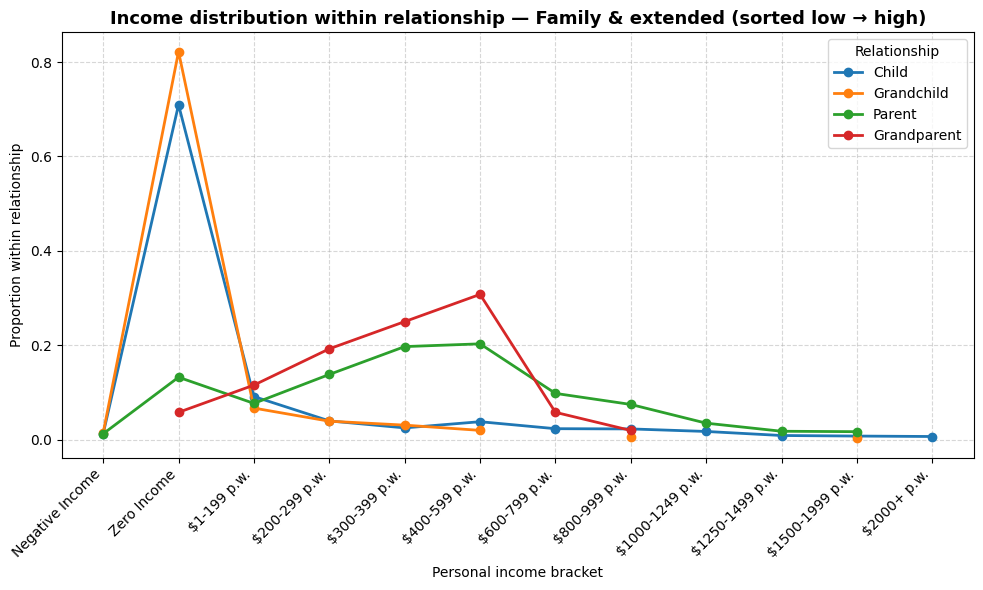

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- 1) Prep ---
df = seed_data.copy()
df["relationship_clean"] = df["relationship"].astype(str).str.strip()
df["inc_clean"] = df["persinc"].astype(str).str.strip()

# Robust sorter: Negative < Zero/No income < numeric ranges < 2000+ ; push 'Not stated/Refused' to the end
def income_sort_key(x: str):
    s = x.strip().lower()
    if "negative" in s:
        return -2
    if "zero" in s or "no income" in s:
        return -1
    if "not stated" in s or "refused" in s or "unknown" in s:
        return 10**9  # far right
    t = s.replace("$", "").replace(",", "").replace("–", "-").replace("+", "")
    parts = t.split("-")
    try:
        return int(parts[0])  # start of range, e.g. 200 in "$200-399"
    except Exception:
        return 10**9

income_order = sorted(df["inc_clean"].dropna().unique(), key=income_sort_key)
df["inc_clean"] = pd.Categorical(df["inc_clean"], categories=income_order, ordered=True)

# --- 2) Proportions within relationship (each line sums to 1 across income) ---
prop_df = (
    df.groupby(["relationship_clean", "inc_clean"])
      .size()
      .groupby(level=0, group_keys=False)
      .apply(lambda s: s / s.sum())
      .reset_index(name="proportion")
)
# Hide zeros so they don't draw points/segments
prop_df.loc[prop_df["proportion"] == 0, "proportion"] = np.nan

# --- 3) Plot helper ---
palette = plt.cm.tab10.colors

def plot_income_group(rel_list, title, savepath=None):
    plt.figure(figsize=(10, 6))
    for i, rel in enumerate(rel_list):
        sub = prop_df[prop_df["relationship_clean"] == rel]
        if not sub.empty:
            sub = sub.sort_values("inc_clean")
            plt.plot(sub["inc_clean"], sub["proportion"], marker='o',
                     linewidth=2, label=rel, color=palette[i % len(palette)])
    plt.title(title, fontsize=13, weight='bold')
    plt.xlabel("Personal income bracket")
    plt.ylabel("Proportion within relationship")
    plt.legend(title="Relationship", loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=200)
    plt.show()

# --- 4) Make the two plots (legend order fixed by the list order) ---
core = ["Main", "Spouse", "Sibling", "Others"]
fam_ext = ["Child", "Grandchild", "Parent", "Grandparent"]

plot_income_group(core,    "Income distribution within relationship — Core roles (sorted low → high)")
plot_income_group(fam_ext, "Income distribution within relationship — Family & extended (sorted low → high)")
